##Setup

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.model_selection import train_test_split
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 50)

##Load Dataset

In [2]:
import kagglehub
import shutil
path = kagglehub.dataset_download("tomalislam/titanic-dataset-fot-practice")
print("Path to dataset files:", path)
shutil.copytree(path, '/content/dataset', dirs_exist_ok=True, ignore=shutil.ignore_patterns('.nfs*'))

100%|██████████| 29.7k/29.7k [00:00<00:00, 30.8MB/s]

Extracting files...
Path to dataset files: /root/.cache/kagglehub/datasets/tomalislam/titanic-dataset-fot-practice/versions/4


'/content/dataset'

In [3]:
dfTest = pd.read_csv('/content/dataset/testEncoded.csv')
dfTrain = pd.read_csv('/content/dataset/trainEncoded.csv')

##Split data

In [6]:
target = 'survived'
xTrain = dfTrain.drop(target,axis=1)
xTest = dfTest.drop(target,axis=1)
yTrain = dfTrain[target]
yTest = dfTest[target]

In [7]:
print(f'Test Shape :{dfTest.shape}')
print(f'Train Shape :{dfTrain.shape}')
print(f'feature train shape : {xTrain.shape}')
print(f'output train shape :  {yTrain.shape}')
print(f'feature test shape : {xTest.shape}')
print(f'output test shape :  {yTest.shape}')

Test Shape :(179, 13)
Train Shape :(712, 13)
feature train shape : (712, 12)
output train shape :  (712,)
feature test shape : (179, 12)
output test shape :  (179,)


##Filter Numerical And Categorical Columns

In [10]:
numCol = ["age", "sibsp", "parch", "fare"]
catCol = xTrain.columns.difference(numCol).to_list()

print("Numerical columns:", numCol)
print("Categorical columns:", catCol)

Numerical columns: ['age', 'sibsp', 'parch', 'fare']
Categorical columns: ['adult_male', 'alone', 'embarked_Q', 'embarked_S', 'pclass', 'sex', 'who_man', 'who_woman']


##Valid Outliers detect

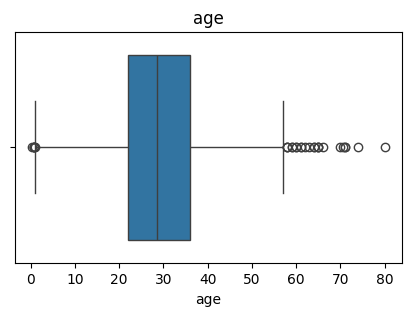

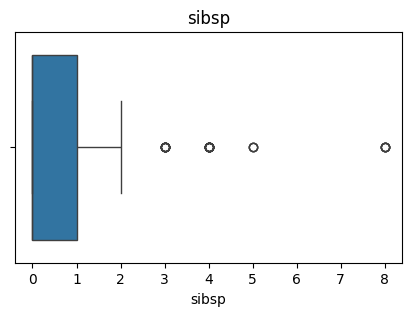

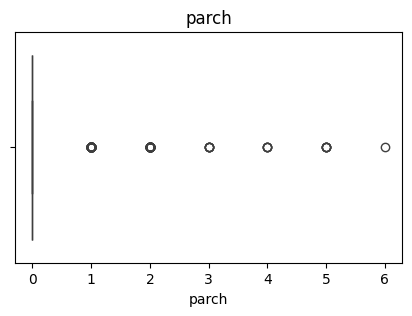

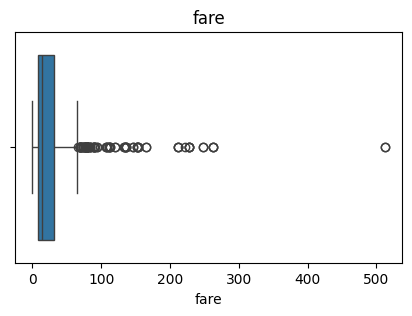

In [13]:
for col in numCol:
  plt.figure(figsize=(5,3))
  sns.boxplot(x=xTrain[col])
  plt.title(col)
  plt.show()

In [14]:
outlierCol = ['age','fare']

##IQR and Capping

###Function for upper and lower bounds compute

In [25]:
def iqrBound(series):
    q1 = series.quantile(.25)
    q3 = series.quantile(.75)
    iqr = q3 - q1
    lowerBound = q1 - 1.5 * iqr
    upperBound = q3 + 1.5 * iqr
    return lowerBound, upperBound

In [26]:
def computeBounds(df, cols):
    bounds = {}
    for col in cols:
        l, u = iqrBound(df[col])
        bounds[col] = (l, u)
    return bounds

###Function for Capping Outliers to lower and upper bound



```
np.where(condition, value_if_true, value_if_false)
```



In [29]:
def computeCapping(df,bounds):
  dfCapped = df.copy(deep=True)
  for col,(l,u) in bounds.items():
    dfCapped[col] = np.where(dfCapped[col] < l ,l,dfCapped[col])
    dfCapped[col] = np.where(dfCapped[col]> u,u,dfCapped[col])
  return dfCapped


In [34]:
testOutlierBounds = computeBounds(xTest, outlierCol)
xTestCapped = computeCapping(xTest,testOutlierBounds)
trainOutlierBounds = computeBounds(xTrain,outlierCol)
xTrainCapped = computeCapping(xTrain,trainOutlierBounds)

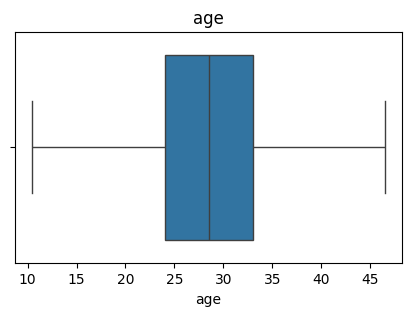

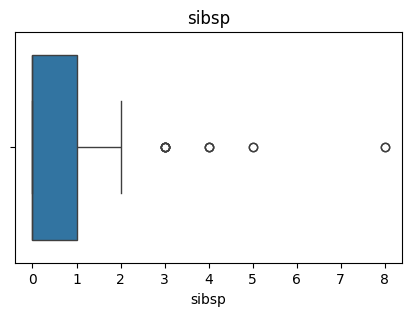

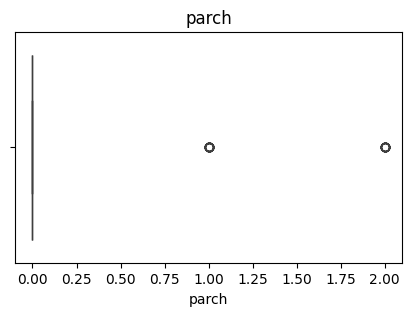

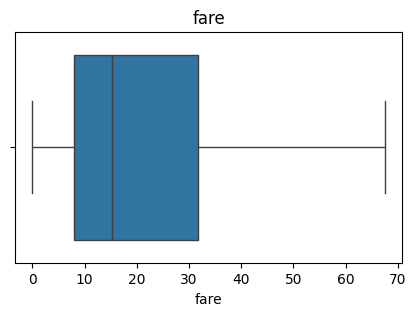

In [35]:
for col in numCol:
  plt.figure(figsize=(5,3))
  sns.boxplot(x=xTestCapped[col])
  plt.title(col)
  plt.show()

##Save Outlier treated sets to csv files

In [37]:
testOut = xTestCapped.copy(deep=True)
testOut[target] = yTest
trainOut = xTrainCapped.copy(deep=True)
trainOut[target] = yTrain

In [38]:
testOut.to_csv('testOutlier.csv',index=False)
trainOut.to_csv('trainOutlier.csv',index=False)